# Bike-Share Analysis: How Do Members and Casual Riders Differ?

**Business question.** Divvy, Chicago's bike-share service, earns more from annual members than from casual riders who buy single rides or day passes. The marketing team wants to convert casual riders into members. To design that campaign, we first need to understand **how the two groups use the bikes differently**.

This notebook follows the six steps of the Google Data Analytics process: **Ask, Prepare, Process, Analyse, Share, Act.**

## 1. Prepare: load the data

The data is Divvy's public trip data (one CSV per month), published by Lyft Bikes and Scooters under the [Divvy Data License Agreement](https://divvybikes.com/data-license-agreement). Each row is one ride, with start and end time, stations, coordinates, bike type and rider type (`member` or `casual`). The data contains no personal information about riders.

This analysis covers **12 months, December 2024 to November 2025**. Download them into `data/` with:

```
python src/download_data.py 202412 202501 202502 202503 202504 202505 202506 202507 202508 202509 202510 202511
```

In [1]:
import json, os
from pathlib import Path
import pandas as pd

from src.bikeshare import load_trips, clean_trips, add_features, summarise, top_casual_stations
from src import charts

DATA_DIR = Path(os.environ.get("DATA_DIR", "data"))
IMAGES = Path("images")

raw = load_trips(DATA_DIR)
print(f"{len(raw):,} rides loaded")
raw.head()

5,590,832 rides loaded


,ride_id,rideable_type,started_at,ended_at,start_station_name,end_station_name,start_lat,start_lng,end_lat,end_lng,member_casual
0,6C960DEB4F78854E,electric_bike,2024-12-31 01:38:35.018,2024-12-31 01:48:45.775,Halsted St & Roscoe St,Clark St & Winnemac Ave,41.943632,-87.649083,41.973348,-87.667855,member
1,C0913EEB2834E7A2,classic_bike,2024-12-21 18:41:26.478,2024-12-21 18:47:33.871,Clark St & Wellington Ave,Halsted St & Roscoe St,41.936497,-87.647539,41.943632,-87.649083,member
2,848A37DD4723078A,classic_bike,2024-12-21 11:41:01.664,2024-12-21 11:52:45.094,Sheridan Rd & Montrose Ave,Broadway & Barry Ave,41.961670,-87.654640,41.937582,-87.644098,member
3,3FA09C762ECB48BD,electric_bike,2024-12-26 13:07:27.526,2024-12-26 13:10:54.130,Aberdeen St & Jackson Blvd,Green St & Randolph St*,41.877726,-87.654787,41.883602,-87.648627,member
4,E60317ADD1A87488,electric_bike,2024-12-13 15:17:55.063,2024-12-13 15:27:32.583,Paulina St & Flournoy St,Fairfield Ave & Roosevelt Rd,41.873061,-87.669135,41.866624,-87.694521,member


## 2. Process: clean the data

Problems found in the raw data and how they are handled:

- **Rides from outside the study year** are removed. Each monthly file also holds a few rides from the end of the previous month.
- **Duplicate ride IDs** are removed, keeping one copy.
- **Rides shorter than 1 minute** are removed. These are usually false starts or riders re-docking a bike.
- **Rides with an end time before the start time** are removed, as they are data errors.
- **Rides longer than 24 hours** are removed. These are usually lost or stolen bikes, not real trips.
- **Missing station names** are kept for time-based analysis, but excluded from the station ranking.

In [2]:
# Keep one full year: December 2024 to November 2025
trips, log = clean_trips(raw, start="2024-12-01", end="2025-12-01")
print(json.dumps(log, indent=2))
print("Missing start station names:", f"{trips['start_station_name'].isna().mean():.1%}")

{
  "raw_rows": 5590832,
  "duplicates_removed": 0,
  "outside_period_removed": 13,
  "bad_duration_removed": 152382,
  "clean_rows": 5438437,
  "share_kept": 0.9727
}
Missing start station names: 20.2%


In [3]:
trips = add_features(trips)
trips[["started_at", "member_casual", "ride_minutes", "day_of_week", "hour", "season", "distance_km", "round_trip"]].head()

,started_at,member_casual,ride_minutes,day_of_week,hour,season,distance_km,round_trip
0,2024-12-31 01:38:35.018,member,10.179283,Tuesday,1,Winter,3.650714,False
1,2024-12-21 18:41:26.478,member,6.123217,Saturday,18,Winter,0.803561,False
2,2024-12-21 11:41:01.664,member,11.723833,Saturday,11,Winter,2.816748,False
3,2024-12-26 13:07:27.526,member,3.443400,Thursday,13,Winter,0.828841,False
4,2024-12-13 15:17:55.063,member,9.625333,Friday,15,Winter,2.220563,False


## 3. Analyse: compare the two rider groups

In [4]:
summary = summarise(trips)
table = pd.DataFrame({
    "Share of rides": summary["ride_share"],
    "Median ride (min)": summary["median_minutes"],
    "Rides over 30 min": summary["rides_over_30_min_share"],
    "Median distance (km)": summary["median_distance_km"],
    "Weekend share": summary["weekend_share"],
    "Round trips": summary["round_trip_share"],
    "Busiest day": summary["busiest_day"],
    "Busiest hour": summary["busiest_hour"],
}).T
table

,casual,member
Share of rides,0.3542,0.6458
Median ride (min),11.9,8.7
Rides over 30 min,0.1555,0.0539
Median distance (km),1.66,1.65
Weekend share,0.3726,0.2353
Round trips,0.0558,0.0148
Busiest day,Saturday,Thursday
Busiest hour,17,17


## 4. Share: visualise the differences

,start_station,casual_rides
0,DuSable Lake Shore Dr & Monroe St,30892
1,Navy Pier,26647
2,Streeter Dr & Grand Ave,23713
3,Michigan Ave & Oak St,22105
4,DuSable Lake Shore Dr & North Blvd,19054
5,Millennium Park,18811
6,Shedd Aquarium,16736
7,Dusable Harbor,15541
8,Theater on the Lake,15465
9,Michigan Ave & 8th St,11073


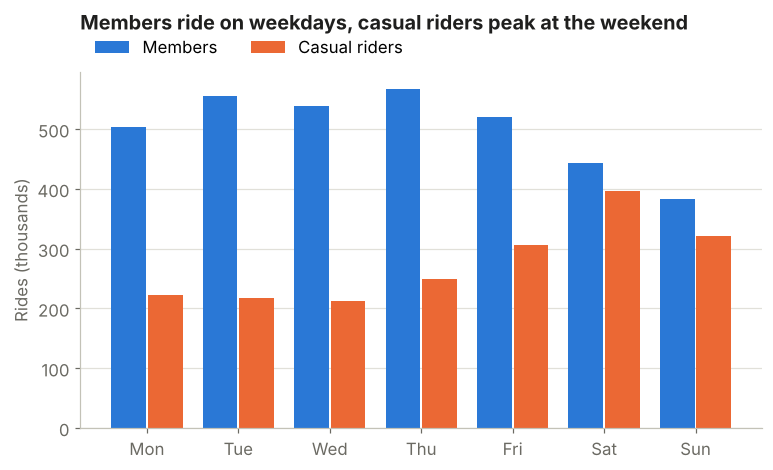

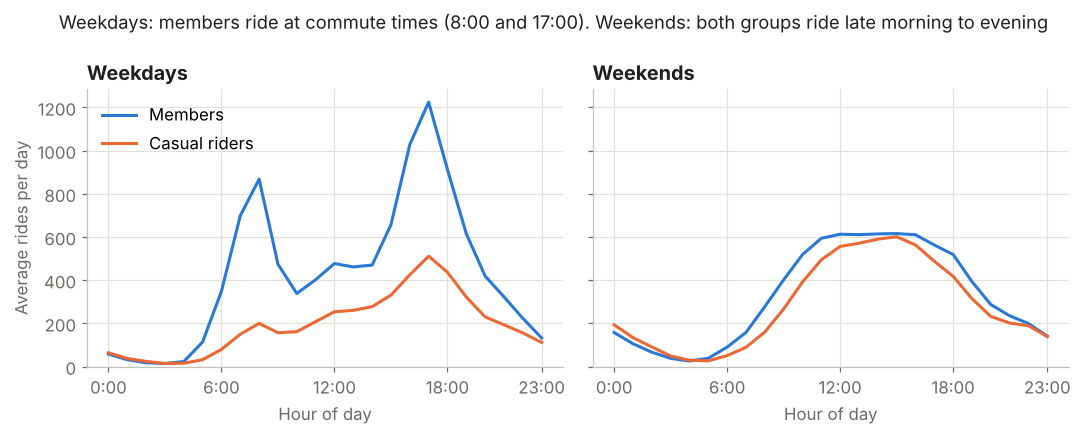

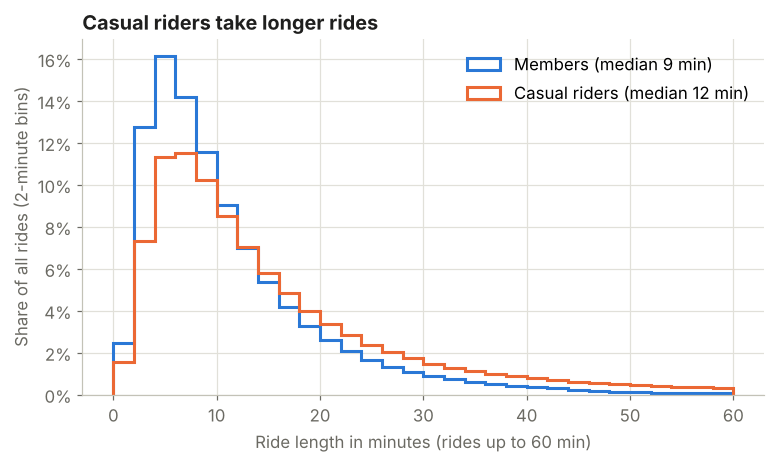

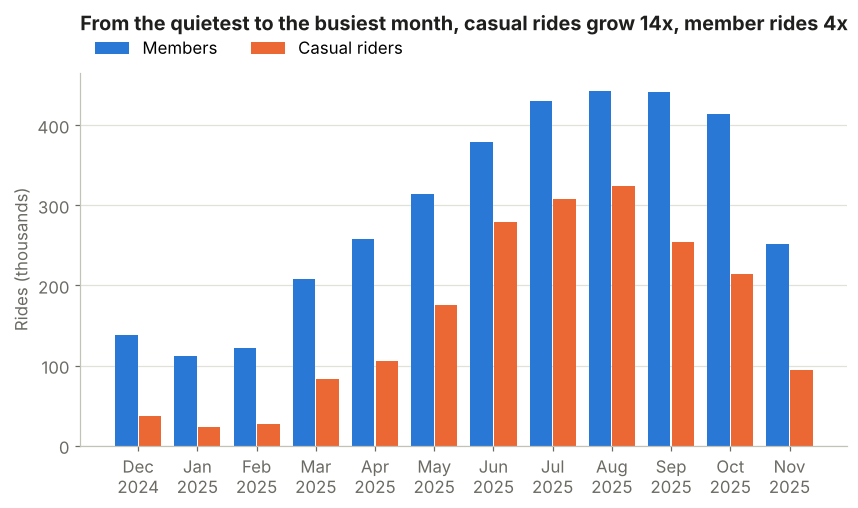

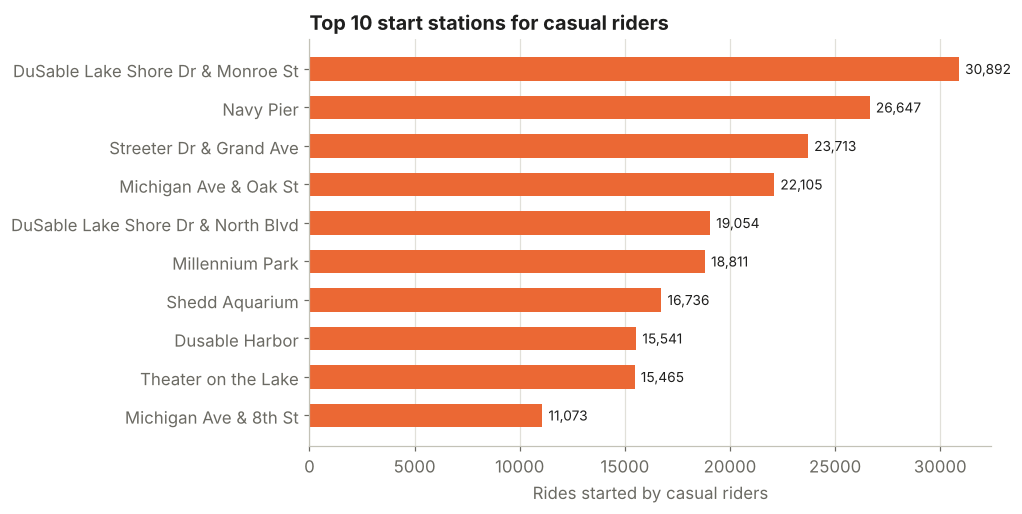

In [5]:
charts.rides_by_day(trips, IMAGES)
charts.rides_by_hour(trips, IMAGES)
charts.ride_duration(trips, IMAGES)
charts.rides_by_month(trips, IMAGES)
stations = top_casual_stations(trips)
charts.top_stations(stations, IMAGES)
stations

In [6]:
Path("results").mkdir(exist_ok=True)
summary["cleaning"] = log
summary["top_casual_stations"] = stations.to_dict(orient="records")
Path("results/summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("Saved results/summary.json and charts in images/")

Saved results/summary.json and charts in images/


## 5. Act: recommendations

See the **Findings** and **Recommendations** sections in the README. They are written from the numbers produced above.